# <p style="color:#690068"> CHAPITRE 3 & TD05 -  EQUATIONS DIFFERENTIELLES </p>

#### <p style="color:#690068">  *Remarque* : Ce notebook propose des exercices de révision sur les équations différentielles. Il propose également des applications aux domaines de la biologie ou de la chimie qui viendront prolonger aux cas d'équations différentielles scalaires autonomes d'ordre 1, ce qui a été fait en BCPST1. </p>

**Importation des bibliothèques utiles :**

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

## I/ Equations différentielles d'ordre $1$ - L'algorithme d'Euler.

### I.1. Introduction.

Les équations différentielles du premier ordre peuvent se mettre, selon les cas, sous la forme générale  

$$\begin{cases} y'(t)&=F(y(t)), t\in I\\ y(t_0)&=y_0 \end{cases} (E_1)  
\text{ ou }  
\begin{cases} y'(t)&=F(t,y(t)), t\in I\\ y(t_0)&=y_0 \end{cases}(E_2 )$$  

On dira que $y:I \rightarrow \mathbb{R}$ est une solution sur $I$ de  l'équation différentielle si $y$ est dérivable sur $I$ et $y'(t)=F(y(t))$ ou $y'(t)=F(t,y(t))$ selon les cas, avec $y(t_0)=y_0$.  

On admettra que la solution au problème ainsi posé existe en tant que fonction définie sur $I$ et qu'elle est unique. Pour autant, dans la plupart des cas, on ne sait pas déterminer explicitement cette solution et nous allons donc mettre en place des méthodes numériques permettant d'approcher la solution de telles équations.

### I.2. La méthode d'Euler explicite pour $y'(t)=f(y(t))$, $y(t_0)=y_0$ :

#### Mise en oeuvre :
On considère une subdivision de $I$, suite de points $(t_n)_{n\in\mathbb{N}}$ définie par $t_n=t_0+nh\in I$, $\forall n\in\mathbb{N}$ et $h$ est un réel strictement positif qu'on pourra choisir aussi petit qu'on le souhaite.  

En pratique, si on veut approcher la solution sur l'intervalle $[t_0, t_f]$, on fixe $n$ (nombre de pas de notre subdivision) et on pose $h=\cfrac{t_f-t_0}{n}$ de telle façon que $t_n = t_f$.  

Si $y$ est la solution de $(E_1)$ alors on a pour tout $n\in\mathbb{N}$ : $y'(t_n)=F(y(t_n))$ et donc, pour $h$ petit,  $y$ étant dérivable sur $I$, on a : 
    $$\cfrac{y(t_n+h)-y(t_n)}{h}\cong y'(t_n)\text{ soit }y(t_{n}+h)\cong y(t_n)+h\cdot F(y(t_n))$$.
Soit, en posant $y_n=y(t_n)$, l'écriture :
$$\forall n\in\mathbb{N}, y_{n+1}\cong y_n+h\cdot F(y_n)$$

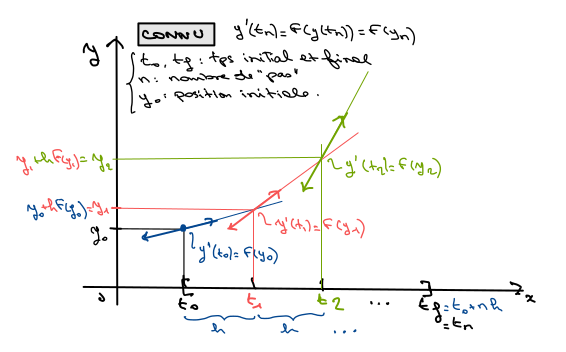

#### Conclusion :
Pour avoir une approximation de la solution sur $I_{+}=I\cap [t_0,+\infty[$, on considère la suite $(y_n)$ définie par son premier terme $y_0=y(t_0)$ (condition initiale) et vérifiant la relation de récurrence :  

$$\begin{cases} t_{n+1}&=t_n+h\\y_{n+1}&=y_n+h\cdot F(y_n) \end{cases}$$

*Question 1 :* Écrire une fonction `euler_explicite(F, t0, tf, y0, n)` dont les arguments sont la fonction $F$, le temps initial, le temps final, la position initiale et le nombre de pas dans la subdivision de l'intervalle $[t_0,t_f]$.  
Elle retournera sous forme de liste l'ensemble des valeurs pris par les suites $(t_n)$ et $(y_n)$ approchant la solution en chaque point de la subdivision.  
On tracera dans un deuxième temps, sur un même graphique, à la fois une approximation numérique de la solution cherchée et la solution obtenue grâce à son cours de BCPST1.

In [ ]:
def eulerExplicite(F, t0, tf, y0, h):
    n =  int((tf -t0)/h) # nombre de subdivisions [entier !]
    T = [0]* (n+1)
    Y = [0]* (n+1) # initialise la solution approchée
    T[0], Y[0] = t0, y0
    for k in range(n): # 0 <= k <= n-1
        T[k+1] = T[k]+h # A compléter
        Y[k+1] = Y[k]+h*F(Y[k])
    return T, Y

**Application 1  :** On considère l'équation différentielle ($Eq_2$) : $y'=-3y$ et $y(0)=2$.  
**Q2.a)** Résoudre cette équation différentielle sur $\mathbb{R}_+$. Tracer le graphe de sa solution sur $[0,3]$ et préciser sa limite en l'infini.

In [ ]:
y1 = lambda t:2*np.exp(-3*t) # A compléter
t0, tf = 0, 3
T = np.linspace(t0, tf, 100)
plt.plot(T, y1(T), 'r')

**Q2.b)** On cherche une solution approchée grâce à la méthode d'Euler. Montrer qu'elle est donnée par une suite géométrique $(y_n)_{n\in\mathbb{N}}$ dont on précisera la raison et le premier terme. Dans quel intervalle doit se situer $h$ pour assurer la stabilité de la solution, autrement dit pour que la solution numérique approchée conserve la même limite en l'infini que la solution $y$ de ($E_1$) ?

**Q2.c)** Le vérifier en utilisant la fonction `euler_explicite()` sur l'intervalle $I=[0,2]$.

In [ ]:
t0, tf = 0, 2
h = 0.01
F = lambda y:-3*y # A compléter
y0 = 2
Td, Y = eulerExplicite(F, t0, tf, y0, h)
plt.plot(Td, Y, label='Euler explicite')
T = np.linspace(t0, tf, 100)
plt.plot(T, y1(T), 'r', label='Solution exacte')
plt.legend(loc='best')

### I.3. La méthode d'Euler explicite pour $y'(t)=F(t,y(t))$, $y(t_0)=y_0$ :

On généralise la méthode précédente en écrivant que pour obtenir une approximation de la solution sur $I_{+}=I\cap [t_0,+\infty[$, on considère la suite $(y_n)$ définie par son premier terme $y_0$ (condition initiale) et vérifiant la relation de récurrence :  

$$\begin{cases} t_{n+1}&=t_n+h\\y_{n+1}&=y_n+h\cdot F(t_n,y_n) \end{cases}$$

**Algorithme d'Euler (2ème version) :**  Écrire une fonction `eulerExplicite2(F, t0, tf, y0, h)` dont les arguments sont la fonction $F$, les bornes de l'intervalle d'étude $[t_0,t_f]$, $y_0$ et le pas $h$, et qui retourne sous forme de liste l'ensemble des valeurs pris par les suites $(t_n)$ et $(y_n)$ approchant la solution en chaque point de la subdivision.

In [ ]:
def eulerExplicite2(F, t0, tf, y0, h):
    n = int((tf-t0)/h) # nombre de subdivisions [entier !]
    T = [0]*(n+1)
    Y = [0]*(n+1) # initialise la solution approchée
    T[0], Y[0] = t0, y0
    for k in range(n): # 0 <= k <= n-1
        T[k+1] = T[k]+h # A compléter
        Y[k+1] = Y[k]+h*F(T[k], Y[k])
    return T, Y

## 2. Equations différentielles d'ordre 1 - Exercices. 

Résoudre les équations différentielles suivantes sur l'intervalle $I$ indiqué et les confronter sur l'intervalle $[t_0, t_f]$ à la solution obtenue par approximation numérique en complétant la ligne de code ci-dessous qui utilise la fonction `eulerExplicite2()` mise en place précédement.

1. $y'-2y+e^x=0$ sur $I=\mathbb{R}$, $y(0)=0$
2. $y'-xy=x$ sur $I=\mathbb{R}$, $y(0)=1$
3. $y'-2y=8x^2-8x$ sur $I=\mathbb{R}$, $y(0)=1/2$
4. $y'+2y=4e^x+\sin x+\cos x$ sur $I=\mathbb{R}$, $y(0)=\cfrac{8}{15}$
5. $y'-2y=\cfrac{-2}{1+e^{-2x}}$ sur $I=\mathbb{R}$, $y(0) = ln(2)$
6. $xy'-y+\ln x=0$ sur $I = \mathbb{R}_+^*$, $y(1)=0$.
7. $(1-x^2)y'+2xy-4x=0$ sur $I=]1, +\infty[$,  $y(2)=-1$
8. $(x+1)y'+xy=x^2-x+1$ sur $I=]-1, +\infty[$, $y(1)=1$


Pour vérifier, on exécutera dans chaque cas :

In [ ]:
t0, tf = 2, 4 # A choisir selon les cas.
h = 0.001
y0 = -1
F = lambda t, y:(4*t-2*t*y)/(1-t**2)
T1, Y1 = eulerExplicite2(F, t0, tf, y0, h)
solution1 = lambda t:3-t**2
plt.plot(T1, Y1, label='Euler explicite')
T = np.linspace(t0, tf, 100)
plt.plot(T, solution1(T), 'k-.', label='solution exacte')
plt.legend(loc='best')

  
**Exercice un peu plus technique :** La technique du "recollement" :   
On considère l'équation différentielle $(E)$ : $xy'-y=x^2-3$ d'inconnue $y$ fonction dérivable sur $\mathbb{R}$.  
- Résoudre $(E)$ sur l'ensemble des fonctions dérivables sur $\mathbb{R}_+^*$ puis sur l'ensemble des fonctions dérivables sur $\mathbb{R}_-^*$.
- On suppose que $(E)$ admet une solution $\varphi$ sur $\mathbb{R}$. Démontrer que $\varphi:x\longmapsto x^2+3+Cx$ où $C$ est un réel.
- Conclure

## 3. Equations différentielles non linéaires d'ordre 1.

**3.1. Exemple d'introduction :** Résolution numérique de l'équation différentielle **non** linéaire : $y'(t)=2y(t)-y^2(t)$, avec $y(0)=1$ dont on montrera plus loin que la solution est $$y(t)=\cfrac{2}{1+e^{-2t}}$$

In [ ]:
F = lambda t, y:2*y-y**2 #A compléter
t0, tf = 0, 3
y0 = 1
h = 0.01
solution = lambda t:2/(1+np.exp(-2*t))
Td, Y = eulerExplicite2(F, t0, tf, y0, h)
plt.plot(Td, Y , 'r', label='Euler explicite')
T=np.linspace(t0, tf, 100)
plt.plot(T, solution(T), 'b-.', label='Solution exacte')
plt.legend(loc='best')

### **Exercice 2 du TD05 : Cinétique chimique**

In [ ]:
T=np.array([[0,60,108,162,230,326,363,449,527,612,709,822,947,1088,1234,1678,1974],
            [0.005,0.00473,0.00446,0.00419,0.00392,0.00366,0.0034,0.00314,0.00288,0.00263,0.00238,0.00213,0.00189,0.00164,0.0014,0.00116,0.00093]])

In [ ]:
L, C = T.shape
print(f"nb de lignes = {L} et nb de colonnes = {C}")

**Question 1.a) :** Traçons dans deux fenêtres distinctes la courbe représentant `c` en fonction de `T` et celle représentant `c'` en fonction de `T` après avoir évalué numériquement `c'`

In [ ]:
def evalvitesses1(T):
    """ on estime que C'[k] = (C[k+1]-C[k])/(T[k+1]-T[k]) """
    Tvitesses = [0]*(...)
    for k in range(...):
        Tvitesses[k]=...
    return Tvitesses

In [ ]:
Tv = evalvitesses1(T)
plt.subplot(211)
plt.plot(T[0], T[1], 'bo')
plt.subplot(212)
plt.plot(T[...], Tv, 'ro-.')

In [ ]:
def evalvitesses2(T):
    """ on estime ici que C'[k] = (C[k+1]-C[k-1])/(T[k+1]-T[k-1]) """
    Tvitesses = [0]*C # on ne calculera pas Tvitesses[0] et Tvitesses[C-1] qui resteront nuls
    for k in range(...):
        Tvitesses[k]=(...)/(...)
    return Tvitesses

In [ ]:
Tv2 = evalvitesses2(T)
plt.subplot(211)
plt.plot(T[0], T[1], 'bo')
plt.subplot(212)
plt.plot(T[0, 1:-1], Tv2[1:-1], 'bo-.')

**Question 1.c) :** Fonction Python `dteRegression()` qui, pour $X$ et $Y$ donnés en entrée, renvoie les coefficients $a$ et $b$ de la droite de régression de la série statistique $(X,Y)$.

In [ ]:
def dteRegression(X:list, Y:list) -> tuple:
    """ On n'utilise pas directement : a, b = np.polyfit(X, Y, 1) 
        mais on s'autorise le recours à la fonction np.sum() """
    assert len(X) == len(Y)
    n = len(X)
    mx, my = ..., ...
    sx, sy = ..., ...
    sxy = ... - mx*my
    a = ...
    b = ...
    return a, b

Comment en déduire deux valeurs possibles pour l'ordre $n$ de la réaction ?

In [ ]:
def grapheMethodeDiff(T, Tv):
    """ renvoie les valeurs estimées de n et de k """
    X = np.log(T[1, 1:C-1])
    Y = np.log(-Tv[1:C-1])
    plt.plot(X, Y, 'or')
    a, b = dteRegression(X, Y)
    # ou a, b = np.polyfit(X, Y, 1)
    plt.plot(X, a*X+b)
    return a, np.exp(b)

In [ ]:
n, k = grapheMethodeDiff(T, Tv2)
print(f"on estime que n = {n} et que k vaut : {k}")

**Question 2.a** avec l'hypothèse $n=1$.

In [ ]:
plt.plot(T[0], ...), 'or')
c, d = dteRegression(T[0], ...)
# c, d = np.polyfit(T[0], np.log(T[1]), 1)
plt.plot(T[0], c*T[0]+d, 'k')

In [ ]:
k = ... # constante de vitesse de reaction
plt.plot(T[0], T[1], 'or', label='valeurs expérimentales')
plt.plot(T[0], ..., 'vk', label='valeurs modélisées (ordre 1)')
plt.legend(loc='best')
print(f"la valeur de k estimée est de : {k}")

**Question 2.a)** avec l'hypothèse $n=2$ :

In [ ]:
plt.plot(T[0], ..., 'ob')
c2, d2 = dteRegression(T[0], ...)
plt.plot(T[0], c2*T[0]+d2, 'k')

**Conclusion :** On retient l'hypothèse $n=1$ avec $k=8.8e-4$ et donc $t_{1/2}=np.log(2)/k\sim 787.7s$

### **CHAPITRE + TD5-Exercice 3**

### 3.2.1. Introduction au modèle logistique : le modèle malthusien

On a $N'(t)=rN(t)$ avec $N(0)=N_0$ où $r=0.5 an^{-1}$ et $N_0=2.10^5$ T.

In [ ]:
r = 0.5 # an^{-1}
N0 = 2e5 # Tonnes
N = lambda t:...
print('la population double en t1 = ', ..., 'années')  # A compléter
Td = np.linspace(0, 4, 100)
plt.plot(Td, N(Td), 'r')
plt.hlines(2*N0, 0, 4)
plt.grid()

### 3.2.2. Le modèle de Verhulst.

$\begin{cases} N'(t)&=rN(t)\left(1-\cfrac{N(t)}{K}\right)=F(N(t))\text{ , } t\in \mathbb{R}_+^*\\ N(0)&=N_0 \end{cases}$, avec : $F(x) = rx\left(1-\cfrac{x}{K}\right)$.

**Activité :** Comparer l'allure des solutions selon que $N_0<K/2$, $K/2<N_0<K$, $N_0=K$ et $N_0>K$.

In [ ]:
r, K = 0.5, 2e6
t0, tf = 0, 14
h = 0.2
F = lambda t, y:...  # A compléter
Td1, Y1 = eulerExplicite2(F, t0, tf, K/10, h)
Td2, Y2 = eulerExplicite2(F, t0, tf, 0.7*K, h)
Td3, Y3 = eulerExplicite2(F, t0, tf, K, h)
Td4, Y4 = eulerExplicite2(F, t0, tf, 1.5*K, h)
plt.plot(Td1, Y1, label='Euler (N0 < K/2)')
plt.plot(Td2, Y2, label='Euler (K/2 < N0 < K)')
plt.plot(Td3, Y3, label='Euler (N0 = K')
plt.plot(Td4, Y4, label='Euler (N0 > K)')
plt.grid()
plt.legend(loc='best')

**Solution analytique (cf exercice 3 du TD) :**

In [ ]:
N0 = K/10
sol = lambda t:...
X1 = np.linspace(t0, tf, 100)
plt.plot(X1, sol(X1), label = 'Solution exacte')
plt.plot(Td1, Y1, label='solution approchée')
plt.legend(loc='best')
plt.grid()

### 3.2.3. Pêche avec prélèvements constants.

In [ ]:
r = 0.5 # 1 / an
K = 2e6 # tonnes
P = 2e5 # Prélèvement dû à la pèche en tonnes / an
F = lambda y:... # A compléter
t0, tf = 0, 30 # années
h = 0.1 # années

In [ ]:
def verhulstAvecPrelevements(F, t0, tf, N0, h):
    n = int((tf-t0)/h)
    poisson = [0]*(n+1) # tonnes
    poisson[0] = N0
    for pas in range(n):
        Stock = ... # Nouveau stock de poissons
        if Stock>0:
            poisson[pas+1] = ... # A compléter
        else:
            poisson[pas+1] = ... # A compléter
    return poisson

In [ ]:
def graphes(F, t0, tf, h):
    n = int((tf-t0)/h)
    temps = h*np.arange(n+1)
    for N0 in [1.56e6, 1e6, 0.56e6, 0.55e6, 0.5e6]:
        poisson = verhulstAvecPrelevements(F, t0, tf, N0, h)
        plt.plot(temps, poisson, label='N0 = '+str(int(N0)))
    plt.grid(True)
    plt.legend(loc = 'best')
    plt.xlabel('Temps en année')
    plt.ylabel('Quantité de poissons en tonnes')
    plt.show()

In [ ]:
graphes(F, t0, tf, h)

In [ ]:
def etatsStationnaires():
    P1 = np.poly1d([...]) # Création du polynôme grâce à la bibliothèque numpy
    r1, r2 = ... # obtention des racines
    return r1, r2

In [ ]:
r1, r2 = etatsStationnaires()
print('les états stationnaires sont r1 = '+str(r1)+' et r2 = '+str(r2))

In [ ]:
Pmax = r*K/4
print(0.8*Pmax)

### 3.2.5. Modèle de Gompertz

In [ ]:
F = lambda y:r*np.log(K/y)*y # A compléter

In [ ]:
r, K = 0.5, 2e6
N0 = 0.5*K
t0, tf = 0, 14
h = 0.1
T, N = eulerExplicite(F, t0, tf, N0, h)

In [ ]:
plt.plot(T, N, 'r')
Tc = np.linspace(t0, tf, 100)
sol = lambda t:... # A compléter
plt.plot(Tc, sol(Tc))

## 4. Equations linéaires d'ordre 2

Résoudre les $ED$ suivantes d'inconnue $y$ supposée deux fois dérivable sur $\mathbb{R}$.  

1. $y''+y=e^x$  
2. $y''-4y'+4y=7\sin x-\cos x$ ; On cherchera une solution particulière de la forme $y:x\longmapsto a\sin x+b\cos x$, $(a,b)\in\mathbb{R}^2$ 
3. $y''-4y'+4y=xe^{2x}+2x$ ; On pensera à superposer les solutions.
4. $y''-3y'+2y=xe^x$   
5. $y''-3y'+2y=xe^{-2x}$
6. $y''-3y'+2y=x(e^x+e^{-2x})$